# Tutorial Class 10 Set 01

In [1]:
library(tidyverse) # Core tidyverse for wrangling and plotting
library(patchwork) # Combine multiple plots
library(jsonlite)  # For reading JSON files
library(DBI)       # For working with databases
library(duckdb)    # For working with duckdb databases

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.0     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘jsonlite’


The following object is masked from ‘package:purrr’:

    flatten




## Prepare these Exercises before Class

### Exercise 1

In [2]:
# Load the data
auction_results <-
  read_csv("../../../../data/auction_results.csv")

# Examine the structure
glimpse(auction_results)

Rows: 7463 Columns: 7
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (4): auction_id, item_id, seller_id, winner_id
dbl  (2): final_price, num_bids
dttm (1): auction_end_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Rows: 7,463
Columns: 7
$ auction_id       <chr> "A00001", "A00002", "A00003", "A00004", "A00005", "A0…
$ item_id          <chr> "I00001", "I00002", "I00003", "I00004", "I00005", "I0…
$ seller_id        <chr> "S00032", "S00027", "S00012", "S00027", "S00003", "S0…
$ final_price      <dbl> 141.3800, 110.4400, 286.0400, 172.5300, 195.2600, 151…
$ num_bids         <dbl> 15, 10, 17, 12, 14, 13, 9, 20, 14, 17, 19, 16, 10, 11…
$ winner_id        <chr> "B00038", "B00084", "B00093", "B00133", "B00049", "B0…
$ auction_end_date <dttm> 2024-12-04 06:00:00, 2024-12-20 18:00:00, 2025-01-07…


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.
`geom_smooth()` using formula = 'y ~ x'


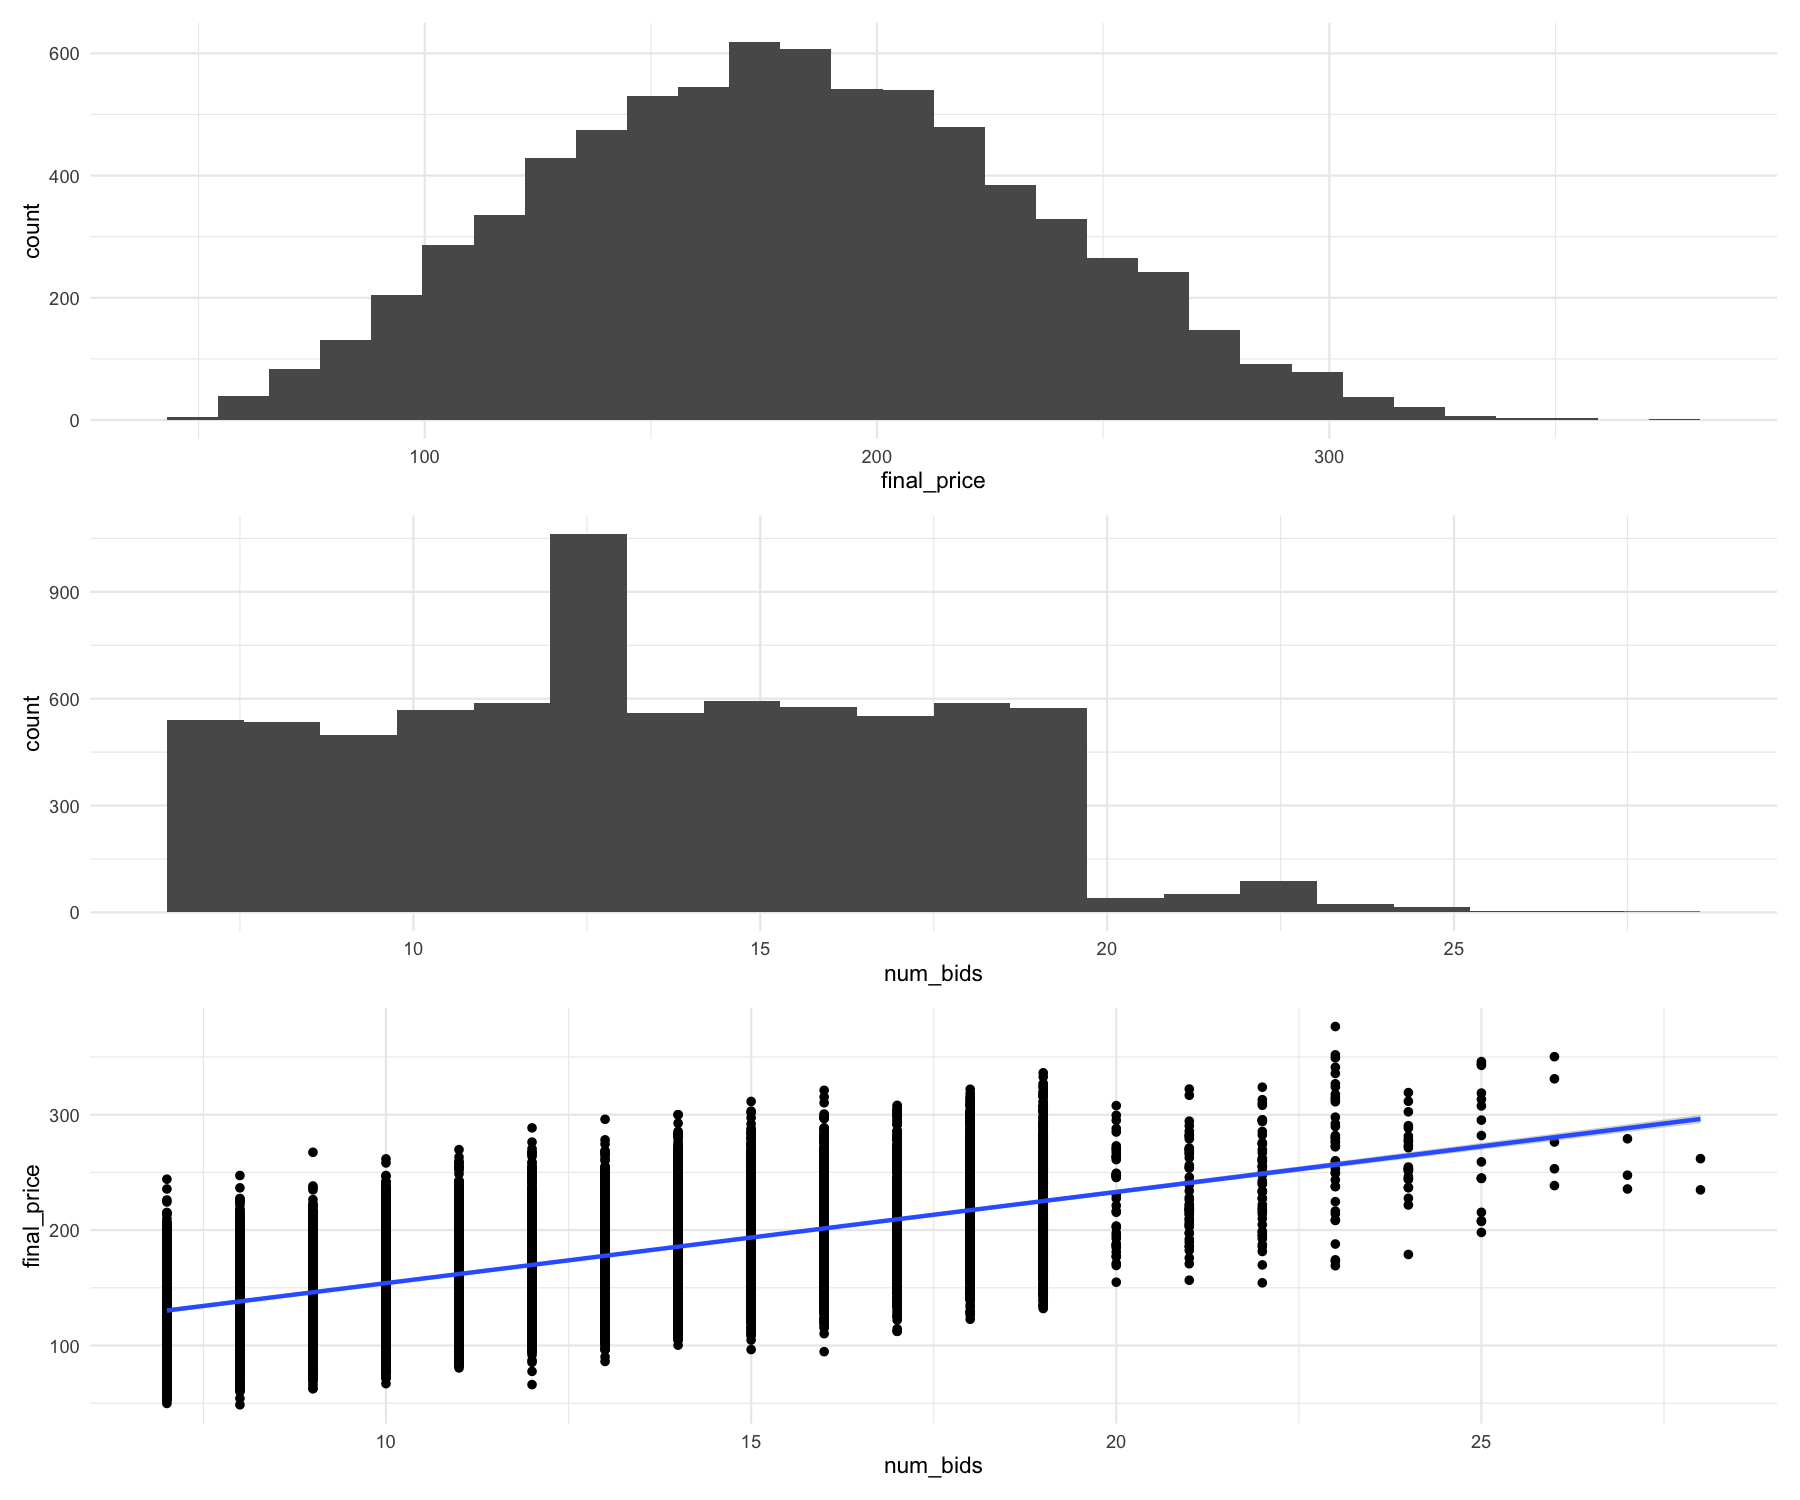

In [3]:
options(repr.plot.width = 12, repr.plot.height = 10, repr.plot.res = 150)

p1 <-
  auction_results |>
  ggplot() +
  geom_histogram(aes(x = final_price)) +
  theme_minimal()

p2 <-
  auction_results |>
  ggplot() +
  geom_histogram(aes(x = num_bids), bins = 20) +
  theme_minimal()

p3 <-
  auction_results |>
  ggplot(aes(
    x = num_bids,
    y = final_price)
    ) +
  geom_point() +
  geom_smooth(method = "lm") +
  theme_minimal()

p1 / p2 / p3

In [4]:
seller_profile <- 
  auction_results |>
  group_by(seller_id) |>
  summarise(
    n_auctions    = n(),
    median_price  = median(final_price, na.rm = TRUE),
    median_bids   = median(num_bids, na.rm = TRUE),
    share_missing_winner = sum(is.na(winner_id)) / n_auctions,
    .groups = "drop"
  ) |>
  arrange(desc(n_auctions))

### Exercise 2

In [5]:
bids_json <- stream_in(file("../../../../data/bids.jsonl"))

head(bids_json, 2)

opening file input connection.



 Imported 99875 records. Simplifying...


closing file input connection.

ERROR while rich displaying an object: Error in vapply(part, function(col) {: values must be length 2,
 but FUN(X[[3]]) result is length 3

Traceback:
1. sapply(x, f, simplify = simplify)
2. lapply(X = X, FUN = FUN, ...)
3. FUN(X[[i]], ...)
4. tryCatch(withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         return(NULL)
 .     prepare_content(is.raw(rpr), rpr)
 . }, error = error_handler), error = outer_handler)
5. tryCatchList(expr, classes, parentenv, handlers)
6. tryCatchOne(expr, names, parentenv, handlers[[1L]])
7. doTryCatch(return(expr), name, parentenv, handler)
8. withCallingHandlers({
 .     if (!mime %in% names(repr::mime2repr)) 
 .         stop("No repr_* for mimetype ", mime, " in repr::mime2repr")
 .     rpr <- repr::mime2repr[[mime]](obj)
 .     if (is.null(rpr)) 
 .         re

In [6]:
bids_json <-
  bids_json  |> 
  unnest_wider(bidder, names_sep = "_") |> 
  unnest_wider(device, names_sep = "_")

In [7]:
same_ip <-
  bids_json |>
  distinct(auction_id, ip_address, bidder_id) |>
  count(auction_id, ip_address) |>
  filter(n > 1) |>
  arrange(desc(n))

In [8]:
auto_bids <-
  bids_json |>
  group_by(auction_id) |>
  summarise(
    num_auto_bids = sum(auto_bid_flag, na.rm = TRUE),
    total_bids    = n(),
    share_auto    = num_auto_bids / total_bids
  ) |>
  arrange(desc(num_auto_bids))

In [9]:
same_ip_auctions <-
  same_ip |>
  group_by(auction_id) |>
  summarise(
    n_shared_ips = n(),           # how many IPs in this auction were used by 2+ bidders
    max_shared_n = max(n),        # largest number of bidders sharing a single IP
    .groups = "drop"
  )

shill_signals <- 
  same_ip_auctions |>
  left_join(auto_bids, by = "auction_id") |> 
  arrange(desc(n_shared_ips), desc(share_auto))

## In-Class Exercises

### Exercise 3

In [10]:
con <- dbConnect(duckdb(), dbdir = "../../../../data/auctions.duckdb")

dbListTables(con)

[1] "auctions" "bids"     "items"    "orders"   "users"

In [11]:
tbl(con, "bids")     |> glimpse()
tbl(con, "auctions") |> glimpse()
tbl(con, "users")    |> glimpse()
tbl(con, "items")    |> glimpse()
tbl(con, "orders")   |> glimpse()

Rows: ??
Columns: 4
Database: DuckDB 1.5.2 [root@Darwin 25.5.0:R 4.5.2//Users/zhangfan/Library/Mobile Documents/com~apple~CloudDocs/Fan的文件/我的同步/GitHub/NavigationBA_FBA/data/auctions.duckdb]
$ auction_id <chr> "A00001", "A00001", "A00001", "A00001", "A00001", "A00001",…
$ user_id    <chr> "B00153", "B00062", "B00029", "B00084", "B00017", "B00027",…
$ bid_time   <dbl> 1732836420, 1732864260, 1732904640, 1732906740, 1732921920,…
$ amount     <dbl> 21.43, 35.52, 37.67, 47.99, 59.90, 62.62, 76.15, 85.74, 97.…
Rows: ??
Columns: 4
Database: DuckDB 1.5.2 [root@Darwin 25.5.0:R 4.5.2//Users/zhangfan/Library/Mobile Documents/com~apple~CloudDocs/Fan的文件/我的同步/GitHub/NavigationBA_FBA/data/auctions.duckdb]
$ auction_id <chr> "A00001", "A00002", "A00003", "A00004", "A00005", "A00006",…
$ item_id    <chr> "I00001", "I00002", "I00003", "I00004", "I00005", "I00006",…
$ start_time <dbl> 1732831200, 1734433200, 1735948800, 1731920400, 1735542000,…
$ end_time   <dbl> 1733292000, 1734717600, 1736211600, 17322

In [12]:
bidder_activity <- 
  tbl(con, "bids") |>
  group_by(user_id) |>
  summarise(
    total_bids = n(),
    auctions_participated = n_distinct(auction_id),
    .groups = "drop"
  ) |>
  collect()

In [13]:
# Step 1: rename to make easier to track
bids <- 
  tbl(con, "bids") |>
  rename(bidder_id = user_id)

# Step 2: link bids to the seller whose auction they are participating in
bids_items <- 
  bids |>
  left_join(
    tbl(con, "auctions") |> select(auction_id, item_id),
    by = "auction_id"
  ) |>
  left_join(
    tbl(con, "items") |> select(item_id, seller_id),
    by = "item_id"
  )

# Step 3: how many bids does each bidder make in total?
total_bids_per_bidder <- 
  bids_items |>
  count(bidder_id, name = "total_bids")

# Step 4: how many bids does each bidder make to each seller?
bidder_seller_bids <- 
  bids_items |>
  count(bidder_id, seller_id, name = "bids_to_seller")

# Step 5: find each bidder's highest concentration on one seller
concentration <- 
  bidder_seller_bids |>
  left_join(total_bids_per_bidder, by = "bidder_id") |>
  mutate(seller_share = bids_to_seller / total_bids) |>
  group_by(bidder_id) |> 
  slice_max(seller_share, n = 1) |>
  collect()

In [14]:
median_concentration <- 
  median(concentration$seller_share)

questionable_bidders <-
  concentration |>
  filter(
    seller_share > 2 * median_concentration,
    total_bids >= 10
  )

### Exercise 4

In [15]:
# Step 1: rename to make easier to track
bids <- 
  tbl(con, "bids") |>
  rename(bidder_id = user_id)

# Step 2: link bids to the seller whose auction they are participating in
bids_items <- 
  bids |>
  left_join(
    tbl(con, "auctions") |> select(auction_id, item_id),
    by = "auction_id"
  ) |>
  left_join(
    tbl(con, "items") |> select(item_id, seller_id),
    by = "item_id"
  )

# Step 3: how many bids does each bidder make in total?
total_bids_per_bidder <- 
  bids_items |>
  count(bidder_id, name = "total_bids")

# Step 4: how many bids does each bidder make to each seller?
bidder_seller_bids <- 
  bids_items |>
  count(bidder_id, seller_id, name = "bids_to_seller")

# Step 5: find each bidder's highest concentration on one seller
concentration <- 
  bidder_seller_bids |>
  left_join(total_bids_per_bidder, by = "bidder_id") |>
  mutate(seller_share = bids_to_seller / total_bids) |>
  group_by(bidder_id) |> 
  slice_max(seller_share, n = 1) |>
  collect()

In [16]:
median_concentration <- 
  median(concentration$seller_share)

questionable_bidders <-
  concentration |>
  filter(
    seller_share > 2 * median_concentration,
    total_bids >= 10
  )

### Exercise 5

In [17]:
# Step 1: winners per auction
winners <- 
  tbl(con, "orders") |>
  select(auction_id, winner_id)

# Step 2: distinct auctions each bidder joined
bidder_auctions <- 
  bids_items |>
  distinct(bidder_id, auction_id)

# Step 3: join winners and compute win_rate
win_rates <- 
  bidder_auctions |>
  left_join(winners, by = "auction_id") |>
  mutate(won = bidder_id == winner_id) |>
  group_by(bidder_id) |>
  summarise(
    auctions_participated = n(),
    auctions_won = sum(won, na.rm = TRUE),
    .groups = "drop"
  ) |>
  mutate(win_rate = auctions_won / auctions_participated) |> 
  collect()

In [18]:
shill_metrics <-
  win_rates |> 
  left_join(concentration, by = "bidder_id")

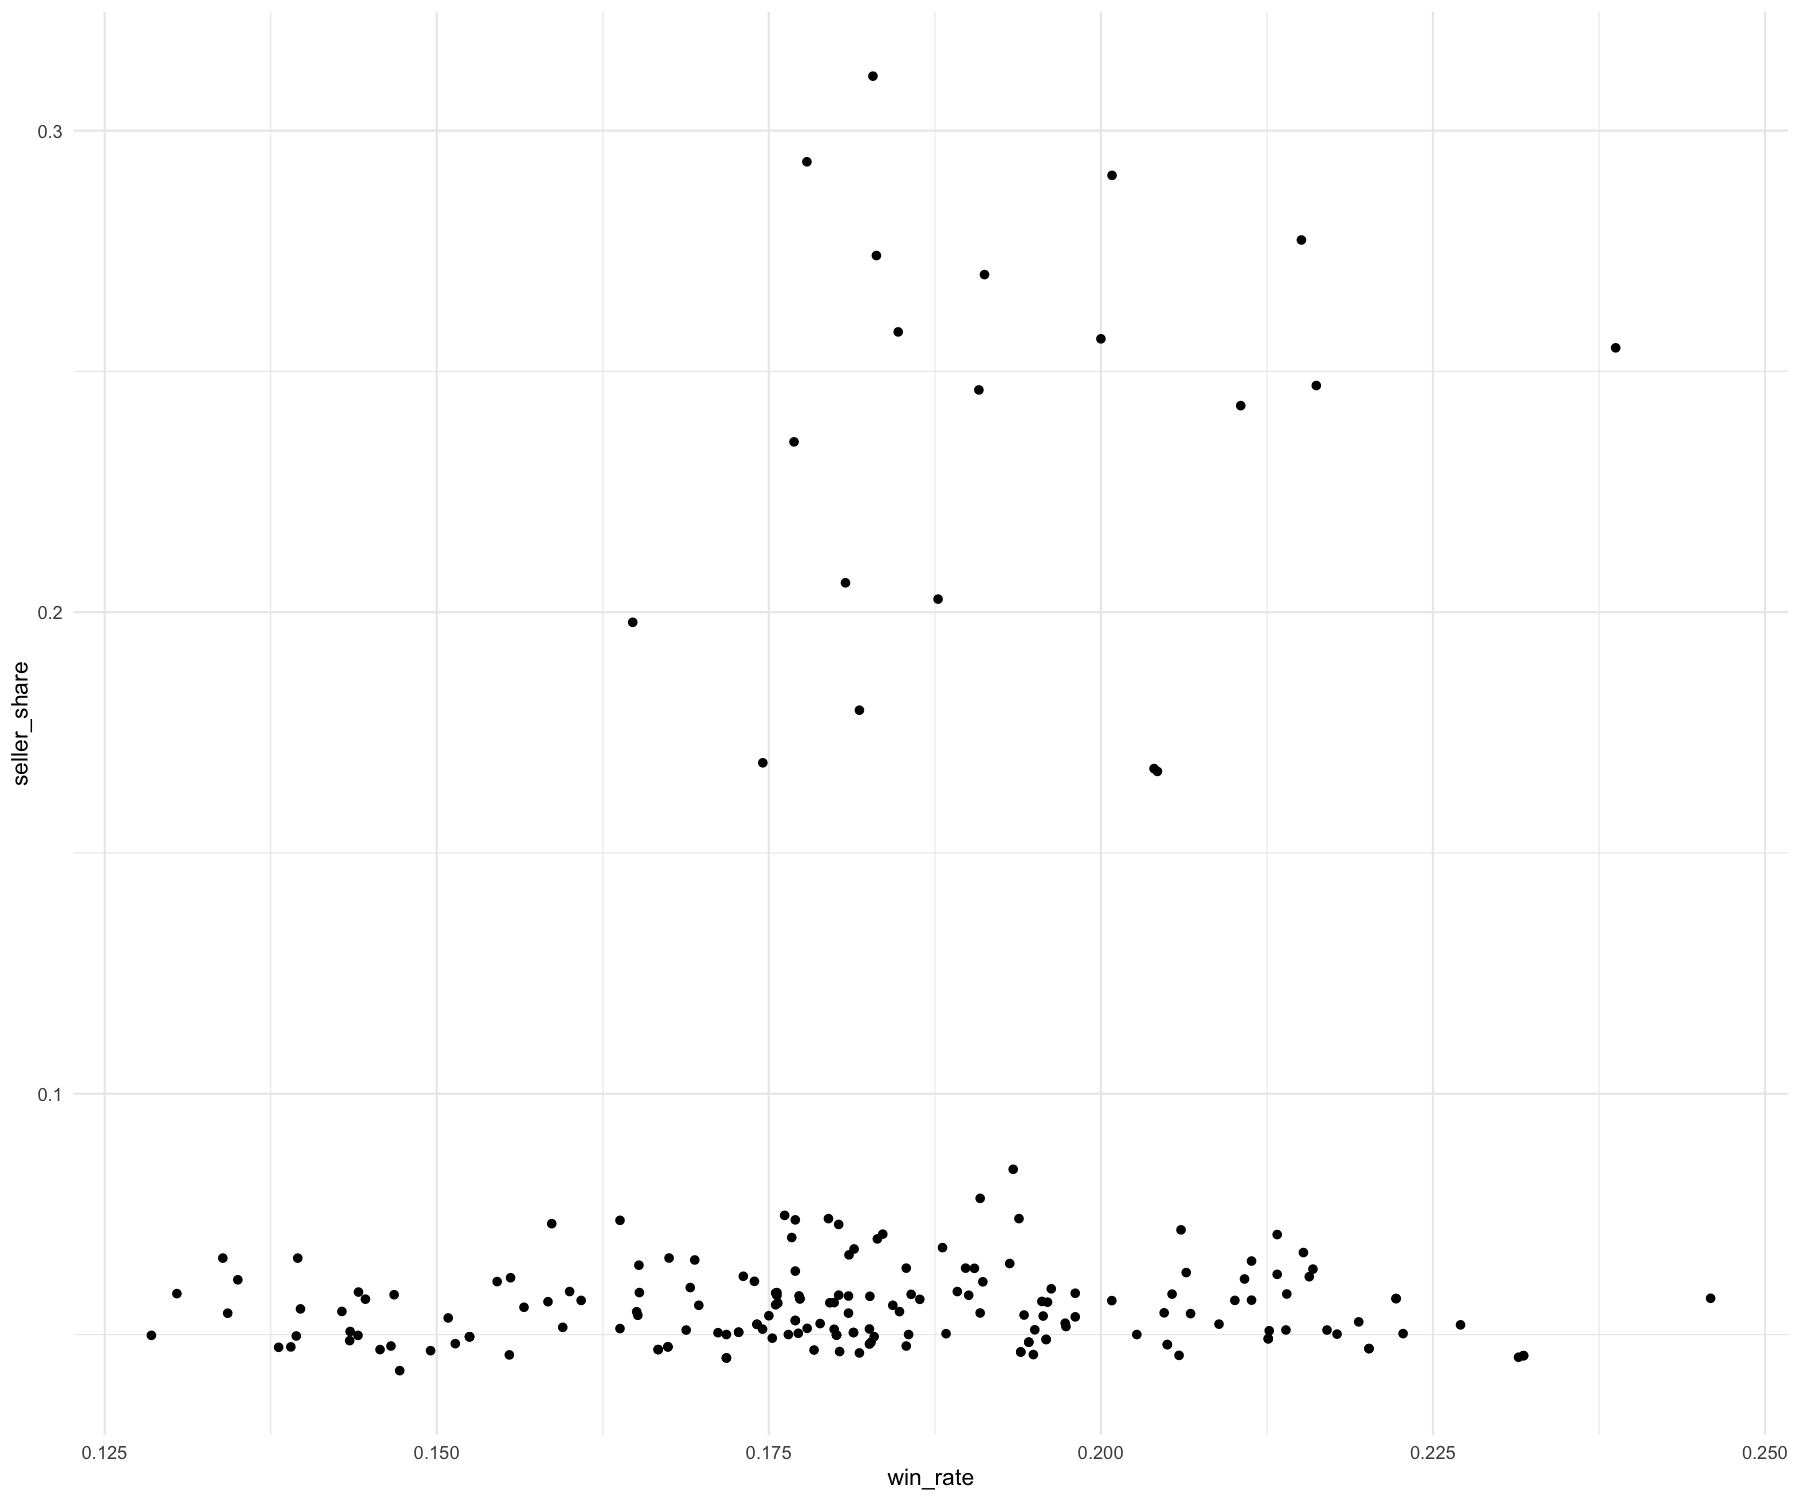

In [19]:
ggplot(shill_metrics) +
  geom_point(aes(x = win_rate, y = seller_share)) +
  theme_minimal()

In [20]:
dbDisconnect(con, shutdown = TRUE)